# Student Dropout Prediction
**Deep Learning Course Project | Topic 16 | Roll Nos. 46, 47, 48**

**Goal:** identify students who may benefit from proactive mentoring using academic and background records.

**Core concept:** feedforward neural network for binary classification, implemented with PyTorch.

### Run this submission
Keep this notebook, `dropout_prediction.py`, `requirements.txt`, and `data.csv` together.
Select a Python kernel with the requirements installed, then choose **Run All**. The submitted copy already contains real executed results. Edit the team names below before submission if your course requires names.

- Roll 46: ____________________
- Roll 47: ____________________
- Roll 48: ____________________

The code below is the same implementation as `dropout_prediction.py`. Functions are defined first; the experiment runs in the final section. No API key, network connection, or synthetic dataset is used during training.


In [1]:
# Run once only if dependencies are missing, then restart the kernel:
# %pip install -r requirements.txt

## 1. Imports and reproducibility
The seed is fixed at 42. The model trains on the CPU. Nominal category codes (such as Course) are one-hot encoded rather than interpreted as quantities. The configuration is fixed before inspecting the test results.

In [2]:
import argparse
import copy
import hashlib
import json
import platform
import random
from dataclasses import asdict, dataclass
from pathlib import Path

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    balanced_accuracy_score, brier_score_loss, classification_report,
    confusion_matrix, f1_score, fbeta_score, log_loss, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


@dataclass
class Config:
    seed: int = 42
    epochs: int = 200
    patience: int = 20
    batch_size: int = 64
    learning_rate: float = 0.001
    weight_decay: float = 0.001
    cv_folds: int = 5       # Use 0 to skip; test records never enter CV.
    permutation_repeats: int = 5


# These are category IDs, even though the CSV stores them as integers.
NOMINAL = [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]
OTHER_FEATURES = [
    "Application order", "Daytime/evening attendance", "Displaced",
    "Educational special needs", "Debtor", "Tuition fees up to date", "Gender",
    "Scholarship holder", "Age at enrollment", "International",
    "Unemployment rate", "Inflation rate", "GDP",
]
SEMESTER_FEATURES = [
    f"Curricular units {semester} sem ({measure})"
    for semester in ("1st", "2nd")
    for measure in ("credited", "enrolled", "evaluations", "approved", "grade",
                    "without evaluations")
]
FEATURES = NOMINAL + OTHER_FEATURES + SEMESTER_FEATURES
COLORS = {"early": "#c44949", "full": "#2879b9"}
NAMES = {"early": "First-semester", "full": "Through second semester"}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(1)  # Efficient, reproducible CPU training on small data.
    torch.use_deterministic_algorithms(True)

## 2. Define the task and split the data
The supplied CSV has 4,424 records and 34 predictor columns. Original labels are Graduate (2,209), Dropout (1,421), and Enrolled (794).

We define **Dropout = 1** and **Graduate = 0**. Enrolled students have unresolved outcomes, so they are excluded from supervised training and evaluation. The 3,630 resolved records are split into **60% training, 20% validation, 20% test**, stratified by outcome. Validation chooses stopping and thresholds; the held-out test split is used for final evaluation.

This changes the original team code's task, which grouped Enrolled with Graduate. The resulting metrics should not be compared directly with the earlier screenshots.

In [3]:
def read_features(path, columns):
    """Read real CSV data. A missing file is an error; no synthetic fallback."""
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Dataset not found: {path.resolve()}")
    frame = pd.read_csv(path, sep=None, engine="python", encoding="utf-8-sig")
    frame.columns = frame.columns.str.strip()
    if frame.columns.duplicated().any():
        raise ValueError("Duplicate column names after whitespace removal.")
    missing = sorted(set(columns) - set(frame.columns))
    if missing:
        raise ValueError(f"Required columns missing: {missing}")
    if frame.empty:
        raise ValueError("The input CSV contains no student records.")
    for col in columns:
        frame[col] = pd.to_numeric(frame[col], errors="raise")
    values = frame[columns].to_numpy(dtype=float)
    if np.isinf(values).any():
        raise ValueError("Infinite feature values found; correct the CSV first.")
    return frame


def load_dataset(path):
    frame = read_features(path, FEATURES)
    if "Target" not in frame:
        raise ValueError("Training requires the Target column.")
    frame["Target"] = frame["Target"].astype("string").str.strip().str.lower()
    if frame["Target"].isna().any():
        raise ValueError("Missing target labels found.")
    unknown = set(frame["Target"].unique()) - {"graduate", "dropout", "enrolled"}
    if unknown:
        raise ValueError(f"Unsupported Target values: {sorted(unknown)}")
    duplicates = frame.duplicated(subset=FEATURES + ["Target"])
    # The index is the original zero-based CSV data-row position (not student ID).
    frame = frame.loc[~duplicates, FEATURES + ["Target"]].copy()
    counts = frame["Target"].value_counts().to_dict()
    if min(counts.get("graduate", 0), counts.get("dropout", 0)) < 30:
        raise ValueError("At least 30 resolved examples of each class are required.")
    audit = {
        "rows_used": len(frame), "raw_features": len(FEATURES),
        "removed_exact_duplicates": int(duplicates.sum()),
        "missing_feature_cells": int(frame[FEATURES].isna().sum().sum()),
        "label_counts": counts,
        "dataset_sha256": hashlib.sha256(Path(path).read_bytes()).hexdigest(),
    }
    return frame, audit


def split_dataset(frame, seed):
    resolved = frame.index[frame["Target"] != "enrolled"].to_numpy()
    y = frame["Target"].eq("dropout").astype(int)
    development, test = train_test_split(
        resolved, test_size=0.20, stratify=y.loc[resolved], random_state=seed)
    train, validation = train_test_split(
        development, test_size=0.25, stratify=y.loc[development], random_state=seed)
    # 60% train / 20% validation / 20% test of resolved outcomes.
    splits = {"train": train, "validation": validation, "test": test}
    assert not (set(train) & set(validation) or set(train) & set(test)
                or set(validation) & set(test))
    return y, splits, development

## 3. Preprocess without fitting on validation or test records
Numeric missing values use training medians and numeric features are standardized. Nominal missing values use the training mode and category IDs are one-hot encoded. Unknown categories at prediction time are handled without refitting. Both experiments use exactly the same student splits.

- **First-semester model:** enrollment/background fields plus first-semester academic fields; all second-semester fields excluded.
- **Full model:** includes second-semester academic fields, providing a later-information comparison.

The first-semester model assumes each retained field, especially financial status, is available at that snapshot. This CSV does not establish the exact measurement time of every field.

In [4]:
def make_preprocessor(columns):
    categorical = [c for c in columns if c in NOMINAL]
    numeric = [c for c in columns if c not in NOMINAL]
    return ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
    ], sparse_threshold=0)

## 4. Feedforward neural network
**Encoded input → Dense(64) + ReLU → Dropout(0.20) → Dense(32) + ReLU → Dropout(0.15) → Dense(16) + ReLU → Dense(1).**

Training uses binary cross-entropy with logits, Adam, L2 regularization through weight decay, mini-batches of 64, and early stopping on validation loss. A sigmoid converts the output logit to a score at inference. Dropout layers randomly deactivate hidden units during training; this regularizer is distinct from the student-dropout outcome. The best validation-loss weights are restored.

In [5]:
class DropoutNetwork(nn.Module):
    """Input -> Dense 64 -> Dense 32 -> Dense 16 -> one output logit."""
    def __init__(self, input_size):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_size, 64), nn.ReLU(), nn.Dropout(0.20),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.15),
            nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.layers(x).squeeze(1)


def predict_scores(model, transformed):
    model.eval()  # Disables dropout during inference.
    with torch.no_grad():
        x = torch.as_tensor(np.asarray(transformed), dtype=torch.float32)
        return torch.sigmoid(model(x)).cpu().numpy()


def train_network(x_train, y_train, x_val, y_val, config, seed):
    set_seed(seed)
    model = DropoutNetwork(x_train.shape[1])
    loss_function = nn.BCEWithLogitsLoss()  # Numerically stable sigmoid + BCE.
    optimizer = torch.optim.Adam(
        model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    dataset = TensorDataset(torch.tensor(x_train, dtype=torch.float32),
                            torch.tensor(np.asarray(y_train), dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    best_loss, best_state, stale = float("inf"), None, 0
    history = []
    for epoch in range(1, config.epochs + 1):
        model.train()
        total = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_function(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(yb)
        val_scores = predict_scores(model, x_val)
        val_loss = log_loss(y_val, val_scores, labels=[0, 1])
        history.append({"epoch": epoch, "train_loss": total / len(dataset),
                        "validation_loss": val_loss,
                        "validation_accuracy": accuracy_score(y_val, val_scores >= 0.5)})
        if val_loss < best_loss - 1e-5:
            best_loss, best_state, stale = val_loss, copy.deepcopy(model.state_dict()), 0
            best_epoch = epoch
        else:
            stale += 1
        if stale >= config.patience:
            break
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), best_epoch

## 5. Decision threshold and evaluation
For each model, maximize **F2 on validation data** across thresholds from 0.05 to 0.95. F2 emphasizes dropout recall more than precision. If scores tie, choose the highest threshold. The threshold is frozen before computing test metrics. The precision/recall trade-off plot uses validation data only.

Report accuracy, balanced accuracy, precision, recall, F1, F2, ROC-AUC, average precision, Brier score, and confusion counts. Accuracy alone is insufficient when the classes differ in size. Logistic regression is a baseline using the same training records and preprocessing; neural networks are not assumed to outperform it.

In [6]:
def threshold_table(y_true, scores):
    rows = []
    for threshold in np.linspace(0.05, 0.95, 91):
        pred = scores >= threshold
        rows.append({
            "threshold": float(threshold),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        })
    return pd.DataFrame(rows)


def select_threshold(table):
    # F2 places more emphasis on recall. Highest threshold wins exact ties.
    best = table["f2"].max()
    return float(table.loc[np.isclose(table["f2"], best, rtol=0, atol=1e-12),
                           "threshold"].max())


def compute_metrics(y_true, scores, threshold):
    pred = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "threshold": threshold, "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "roc_auc": roc_auc_score(y_true, scores),
        "average_precision": average_precision_score(y_true, scores),
        "brier_score": brier_score_loss(y_true, scores),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def fit_experiment(frame, y, splits, columns, config):
    preprocessor = make_preprocessor(columns)
    x_train = preprocessor.fit_transform(frame.loc[splits["train"], columns])
    x_val = preprocessor.transform(frame.loc[splits["validation"], columns])
    x_test = preprocessor.transform(frame.loc[splits["test"], columns])
    model, history, epoch = train_network(
        x_train, y.loc[splits["train"]], x_val, y.loc[splits["validation"]],
        config, config.seed)
    baseline = LogisticRegression(max_iter=2000, random_state=config.seed)
    baseline.fit(x_train, y.loc[splits["train"]])
    result = {"columns": columns, "preprocessor": preprocessor, "model": model,
              "baseline": baseline, "history": history, "best_epoch": epoch,
              "input_size": x_train.shape[1], "tables": {}, "thresholds": {},
              "test_scores": {}, "metrics": {}}
    for name, val_scores, test_scores in [
        ("NN", predict_scores(model, x_val), predict_scores(model, x_test)),
        ("LR", baseline.predict_proba(x_val)[:, 1], baseline.predict_proba(x_test)[:, 1]),
    ]:
        table = threshold_table(y.loc[splits["validation"]], val_scores)
        threshold = select_threshold(table)
        result["tables"][name] = table
        result["thresholds"][name] = threshold
        result["test_scores"][name] = test_scores
        result["metrics"][name] = compute_metrics(y.loc[splits["test"]], test_scores, threshold)
    return result

## 6. Robustness and interpretation
Five-fold cross-validation uses **only the 80% development partition**. Every outer fold has an inner train/validation split for early stopping, and preprocessing is fitted on the inner training rows. Both NN and logistic regression use those same training rows. These CV models use less data than the final training split, so their scores are a separate robustness check.

Permutation importance shuffles original feature columns on the held-out test set and measures ROC-AUC decrease; it measures model dependence, not causation. Subgroup recall and false-alarm rates are descriptive checks, with positive/negative sample counts. They do not establish fairness.

In [7]:
def cross_validate(frame, y, development, feature_sets, config):
    """CV uses development records only; each fold has a separate inner validation."""
    records = []
    if config.cv_folds == 0:
        return pd.DataFrame(columns=["feature_set", "model", "fold", "roc_auc"])
    cv = StratifiedKFold(config.cv_folds, shuffle=True, random_state=config.seed)
    for fold, (train_pos, eval_pos) in enumerate(cv.split(development, y.loc[development]), 1):
        outer_train, outer_eval = development[train_pos], development[eval_pos]
        inner_train, inner_val = train_test_split(
            outer_train, test_size=0.20, stratify=y.loc[outer_train],
            random_state=config.seed + fold)
        for key, columns in feature_sets.items():
            preprocessor = make_preprocessor(columns)
            xt = preprocessor.fit_transform(frame.loc[inner_train, columns])
            xv = preprocessor.transform(frame.loc[inner_val, columns])
            xe = preprocessor.transform(frame.loc[outer_eval, columns])
            model, _, _ = train_network(xt, y.loc[inner_train], xv, y.loc[inner_val],
                                         config, config.seed + fold)
            lr = LogisticRegression(max_iter=2000, random_state=config.seed + fold)
            lr.fit(xt, y.loc[inner_train])
            for name, score in [("NN", predict_scores(model, xe)),
                                ("LR", lr.predict_proba(xe)[:, 1])]:
                records.append({"feature_set": key, "model": name, "fold": fold,
                                "roc_auc": roc_auc_score(y.loc[outer_eval], score)})
        print(f"  Cross-validation fold {fold}/{config.cv_folds} complete.", flush=True)
    return pd.DataFrame(records)


def raw_feature_importance(result, test_frame, y_test, config):
    """Shuffle original columns so all one-hot columns for a category stay together."""
    rng = np.random.default_rng(config.seed)
    base = result["metrics"]["NN"]["roc_auc"]
    records = []
    for column in result["columns"]:
        decreases = []
        for _ in range(config.permutation_repeats):
            shuffled = test_frame[result["columns"]].copy()
            shuffled[column] = rng.permutation(shuffled[column].to_numpy())
            scores = predict_scores(result["model"], result["preprocessor"].transform(shuffled))
            decreases.append(base - roc_auc_score(y_test, scores))
        records.append({"feature": column, "auc_decrease_mean": np.mean(decreases),
                        "auc_decrease_std": np.std(decreases)})
    return pd.DataFrame(records).sort_values("auc_decrease_mean", ascending=False)


def subgroup_analysis(test_frame, y_test, scores, threshold):
    masks = {}
    for value in sorted(test_frame["Gender"].dropna().unique()):
        masks[f"Gender code {value:g}"] = test_frame["Gender"].eq(value).to_numpy()
    age = test_frame["Age at enrollment"]
    masks.update({"Age <20": age.lt(20).to_numpy(),
                  "Age 20-25": age.between(20, 25).to_numpy(),
                  "Age >25": age.gt(25).to_numpy()})
    pred, truth = scores >= threshold, np.asarray(y_test)
    records = []
    for group, mask in masks.items():
        positive, negative = mask & (truth == 1), mask & (truth == 0)
        records.append({"group": group, "n": int(mask.sum()),
                        "dropout_n": int(positive.sum()), "graduate_n": int(negative.sum()),
                        "recall": float(pred[positive].mean()) if positive.any() else np.nan,
                        "false_alarm_rate": float(pred[negative].mean()) if negative.any() else np.nan})
    return pd.DataFrame(records)

## 7. Generate the plots and save the models
The nine plot types follow the team's original project structure. Every figure is regenerated from this run. The saved first-semester preprocessing and weights can score another CSV without retraining. `source_row_id` identifies the one-based data-row position in the CSV; it is not a real student ID.

In [8]:
def create_plots(frame, experiments, y_test, cv, importance, fairness, output):
    plots = output / "plots"
    plots.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                         "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})

    def save(fig, name):
        fig.tight_layout()
        fig.savefig(plots / name, dpi=150, bbox_inches="tight")
        plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 4))
    counts = frame["Target"].value_counts()
    bars = ax.bar(counts.index.str.title(), counts.values, color=["#407bb0", "#c44949", "#888888"])
    ax.bar_label(bars, padding=3)
    ax.set(title="Original labels (Enrolled excluded from supervised learning)", ylabel="Records")
    ax.set_ylim(0, counts.max() * 1.15)
    save(fig, "01_class_distribution.png")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for key, result in experiments.items():
        h = result["history"]
        axes[0].plot(h.epoch, h.train_loss, color=COLORS[key], label=NAMES[key] + " train")
        axes[0].plot(h.epoch, h.validation_loss, "--", color=COLORS[key], label=NAMES[key] + " val")
        axes[0].axvline(result["best_epoch"], color=COLORS[key], alpha=0.25)
        axes[1].plot(h.epoch, h.validation_accuracy, color=COLORS[key], label=NAMES[key])
    axes[0].set(title="Binary cross-entropy (best weights restored)", xlabel="Epoch", ylabel="Loss")
    axes[1].set(title="Validation accuracy at threshold 0.50", xlabel="Epoch", ylabel="Accuracy")
    for ax in axes:
        ax.legend(fontsize=8)
    save(fig, "02_training_curves.png")

    fig, ax = plt.subplots(figsize=(7, 5))
    for key, result in experiments.items():
        for name, scores in result["test_scores"].items():
            fpr, tpr, _ = roc_curve(y_test, scores)
            auc = result["metrics"][name]["roc_auc"]
            ax.plot(fpr, tpr, color=COLORS[key], ls="-" if name == "NN" else "--",
                    label=f"{NAMES[key]} {name} (AUC {auc:.3f})")
    ax.plot([0, 1], [0, 1], ":", color="gray")
    ax.set(title="Held-out test ROC curves: resolved outcomes only",
           xlabel="False positive rate", ylabel="True positive rate")
    ax.legend(fontsize=8)
    save(fig, "03_roc_curves.png")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, (key, result) in zip(axes, experiments.items()):
        threshold = result["thresholds"]["NN"]
        ConfusionMatrixDisplay.from_predictions(
            y_test, result["test_scores"]["NN"] >= threshold, labels=[0, 1],
            display_labels=["Graduate", "Dropout"], ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"{NAMES[key]} NN\nValidation-selected threshold {threshold:.2f}")
        ax.grid(False)
    save(fig, "04_confusion_matrices.png")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, (key, result) in zip(axes, experiments.items()):
        table = result["tables"]["NN"]
        for measure, style in [("precision", "--"), ("recall", "-"), ("f2", ":")]:
            ax.plot(table.threshold, table[measure], style, label=measure.title())
        ax.axvline(result["thresholds"]["NN"], color=COLORS[key], alpha=0.7)
        ax.set(title=NAMES[key] + ": validation only", xlabel="Decision threshold", ylabel="Score", ylim=(0, 1.05))
        ax.legend()
    save(fig, "05_threshold_tradeoff.png")

    early = experiments["early"]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for value, name, color in [(0, "Graduate", "#407bb0"), (1, "Dropout", "#c44949")]:
        ax.hist(early["test_scores"]["NN"][np.asarray(y_test) == value],
                bins=np.linspace(0, 1, 26), alpha=0.6, color=color, label=name)
    ax.axvline(early["thresholds"]["NN"], color="black", ls=":", label="Selected threshold")
    ax.set(title="First-semester NN: held-out test score distribution",
           xlabel="Sigmoid dropout score (not calibrated)", ylabel="Records")
    ax.legend()
    save(fig, "06_risk_distribution.png")

    if not cv.empty:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        grouped = cv.groupby(["feature_set", "model"], sort=False).roc_auc
        means, stds = grouped.mean(), grouped.std(ddof=0)
        bars = ax.bar([f"{'First-semester' if k == 'early' else 'Full'}\n{m}"
                       for k, m in means.index], means.values,
                      yerr=stds.values, capsize=4,
                      color=[COLORS[k] if m == "NN" else "#888888" for k, m in means.index])
        ax.bar_label(bars, fmt="%.3f", padding=4)
        ax.set(title="Development-only CV ROC-AUC (error bars: fold SD)", ylabel="ROC-AUC", ylim=(0, 1.08))
        save(fig, "07_cv_comparison.png")

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, (key, table) in zip(axes, importance.items()):
        top = table.head(10).iloc[::-1]
        labels = [s.replace("Curricular units ", "Units ") for s in top.feature]
        ax.barh(labels, top.auc_decrease_mean, color=COLORS[key])
        ax.set(title=NAMES[key] + " NN: test permutation importance",
               xlabel="Mean decrease in ROC-AUC (association, not causation)")
    save(fig, "08_feature_importance.png")

    fig, ax = plt.subplots(figsize=(10, 4.5))
    positions, width = np.arange(len(fairness)), 0.36
    for delta, column, label, color in [(-width / 2, "recall", "Dropout recall", "#407bb0"),
                                      (width / 2, "false_alarm_rate", "Graduate false-alarm rate", "#d99540")]:
        bars = ax.bar(positions + delta, fairness[column], width, label=label, color=color)
        ax.bar_label(bars, fmt="%.2f", fontsize=9)
    ax.set_xticks(positions, [f"{r.group}\nD={r.dropout_n}, G={r.graduate_n}"
                             for r in fairness.itertuples()])
    ax.set(title="First-semester test subgroup audit (descriptive; no fairness guarantee)", ylim=(0, 1.18))
    ax.legend(fontsize=9, loc="upper left")
    save(fig, "09_fairness.png")


def save_model(result, output, key):
    folder = output / "models"
    folder.mkdir(exist_ok=True)
    torch.save({"state_dict": result["model"].state_dict(),
                "input_size": result["input_size"]}, folder / f"{key}_nn.pt")
    joblib.dump(result["preprocessor"], folder / f"{key}_preprocessor.joblib")
    joblib.dump(result["baseline"], folder / f"{key}_logistic.joblib")
    (folder / f"{key}_metadata.json").write_text(json.dumps({
        "feature_columns": result["columns"], "threshold": result["thresholds"]["NN"],
        "best_epoch": result["best_epoch"], "positive_class": "Dropout",
        "negative_class": "Graduate", "snapshot": NAMES[key],
        "score_note": "Uncalibrated sigmoid score; trained on resolved outcomes only.",
    }, indent=2), encoding="utf-8")


def make_risk_report(frame, scores, threshold):
    report = pd.DataFrame({"source_row_id": frame.index.to_numpy() + 1,
                           "dropout_score": scores,
                           "decision_threshold": threshold,
                           "mentoring_flag": np.asarray(scores) >= threshold})
    report["support_priority"] = np.where(report.mentoring_flag,
                                          "Review for mentoring", "Routine follow-up")
    return report.sort_values("dropout_score", ascending=False)

## 8. Run the complete experiment
The optional Enrolled mentoring export contains only unresolved students, and is kept separate from test predictions. These scores come from a resolved-outcome training cohort and are not calibrated probabilities or validated future dropout estimates for Enrolled students. Use flags as a classroom demonstration of supportive human review, not automated academic decisions.

In [9]:
def run_project(data_path="data.csv", output_dir="outputs", config=None):
    config = Config() if config is None else config
    if config.epochs < 1 or config.patience < 1 or config.batch_size < 1:
        raise ValueError("epochs, patience and batch_size must be positive.")
    if config.cv_folds != 0 and config.cv_folds < 2:
        raise ValueError("cv_folds must be 0 or at least 2.")
    if config.permutation_repeats < 1:
        raise ValueError("permutation_repeats must be positive.")
    set_seed(config.seed)
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    frame, audit = load_dataset(data_path)
    y, splits, development = split_dataset(frame, config.seed)
    feature_sets = {"early": [c for c in FEATURES if "2nd sem" not in c], "full": FEATURES}
    print(f"Loaded {len(frame)} real records. Labels: {audit['label_counts']}", flush=True)
    print("Resolved-outcome splits:", {k: len(v) for k, v in splits.items()}, flush=True)
    print("Enrolled outcomes are excluded from training and evaluation.", flush=True)
    assignments = pd.DataFrame({"source_row_id": frame.index + 1, "Target": frame.Target,
                                "split": "enrolled_demo"}, index=frame.index)
    for name, rows in splits.items():
        assignments.loc[rows, "split"] = name
    assignments.to_csv(output / "split_assignments.csv", index=False)

    experiments, metric_rows, importance = {}, [], {}
    y_test = y.loc[splits["test"]]
    test_frame = frame.loc[splits["test"]]
    for key, columns in feature_sets.items():
        print(f"\nTraining {NAMES[key]} NN and logistic baseline...", flush=True)
        result = fit_experiment(frame, y, splits, columns, config)
        experiments[key] = result
        result["history"].to_csv(output / f"{key}_training_history.csv", index=False)
        for model_name, metrics in result["metrics"].items():
            metric_rows.append({"feature_set": key, "model": model_name, **metrics})
            result["tables"][model_name].to_csv(output / f"{key}_{model_name}_validation_thresholds.csv", index=False)
            pred = result["test_scores"][model_name] >= result["thresholds"][model_name]
            report = classification_report(y_test, pred, labels=[0, 1],
                                             target_names=["Graduate", "Dropout"], zero_division=0)
            (output / f"{key}_{model_name}_classification_report.txt").write_text(report, encoding="utf-8")
        print(f"  Best epoch: {result['best_epoch']}; test NN AUC: {result['metrics']['NN']['roc_auc']:.4f}", flush=True)
        save_model(result, output, key)
        importance[key] = raw_feature_importance(result, test_frame, y_test, config)
        importance[key].to_csv(output / f"{key}_feature_importance.csv", index=False)

    cv = cross_validate(frame, y, development, feature_sets, config)
    cv.to_csv(output / "cv_fold_scores.csv", index=False)
    if not cv.empty:
        summary = cv.groupby(["feature_set", "model"]).roc_auc.agg(
            mean="mean", std=lambda scores: scores.std(ddof=0), count="count")
        summary.to_csv(output / "cv_summary.csv")  # Same population SD as the plot.
    metrics = pd.DataFrame(metric_rows)
    metrics.to_csv(output / "test_metrics.csv", index=False)
    predictions = pd.DataFrame({"source_row_id": test_frame.index + 1,
                                "actual_outcome": test_frame.Target.to_numpy(),
                                "actual_dropout": y_test.to_numpy()})
    for key, result in experiments.items():
        for name, score in result["test_scores"].items():
            predictions[f"{key}_{name}_score"] = score
            predictions[f"{key}_{name}_prediction"] = (score >= result["thresholds"][name]).astype(int)
    predictions.to_csv(output / "test_predictions.csv", index=False)
    early = experiments["early"]
    fairness = subgroup_analysis(test_frame, y_test, early["test_scores"]["NN"], early["thresholds"]["NN"])
    fairness.to_csv(output / "subgroup_audit.csv", index=False)

    # Mentor report is only for unresolved records, separate from test evaluation.
    enrolled = frame.loc[frame.Target == "enrolled"]
    if len(enrolled):
        scores = predict_scores(early["model"], early["preprocessor"].transform(enrolled[early["columns"]]))
        mentor = make_risk_report(enrolled, scores, early["thresholds"]["NN"])
        mentor["observed_status"] = "Enrolled - eventual outcome unknown"
        mentor.to_csv(output / "enrolled_mentoring_demo.csv", index=False)
    create_plots(frame, experiments, y_test, cv, importance, fairness, output)
    manifest = {"config": asdict(config), "data_audit": audit,
                "split_sizes": {k: len(v) for k, v in splits.items()},
                "framework": "PyTorch CPU", "python": platform.python_version(),
                "versions": {"torch": torch.__version__, "numpy": np.__version__,
                             "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
                             "matplotlib": matplotlib.__version__, "joblib": joblib.__version__},
                "task": "Dropout versus Graduate; Enrolled excluded from supervised learning",
                "threshold_rule": "Maximum validation F2 on 0.05..0.95 grid; highest threshold on ties",
                "cv_scope": "Development split only, with inner training/validation per fold",
                "dataset_reference": "https://doi.org/10.24432/C5MC89"}
    (output / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print("\nHeld-out test results (positive class = Dropout):")
    print(metrics[["feature_set", "model", "threshold", "accuracy", "precision", "recall", "f1", "roc_auc"]].round(4).to_string(index=False))
    print(f"\nSaved models, plots, metrics and demo mentoring report to {output.resolve()}", flush=True)
    return {"metrics": metrics, "experiments": experiments, "cv": cv,
            "fairness": fairness, "audit": audit, "splits": splits, "output_dir": output}


def predict_new_students(csv_path, model_dir, report_path):
    """Use the saved first-semester model without fitting anything on new rows."""
    folder = Path(model_dir)
    metadata = json.loads((folder / "early_metadata.json").read_text(encoding="utf-8"))
    columns = metadata["feature_columns"]
    frame = read_features(csv_path, columns)
    preprocessor = joblib.load(folder / "early_preprocessor.joblib")
    checkpoint = torch.load(folder / "early_nn.pt", map_location="cpu", weights_only=True)
    model = DropoutNetwork(checkpoint["input_size"])
    model.load_state_dict(checkpoint["state_dict"])
    scores = predict_scores(model, preprocessor.transform(frame[columns]))
    report = make_risk_report(frame, scores, metadata["threshold"])
    report_path = Path(report_path)
    report_path.parent.mkdir(parents=True, exist_ok=True)
    report.to_csv(report_path, index=False)
    print(f"Saved {len(report)} student scores to {report_path.resolve()}")
    return report

In [10]:
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data.csv").is_file():
    raise FileNotFoundError("Open this notebook from the folder containing data.csv.")
CONFIG = Config()  # Default: up to 200 epochs, 5 CV folds.
results = run_project(PROJECT_DIR / "data.csv", PROJECT_DIR / "outputs", CONFIG)

Loaded 4424 real records. Labels: {'graduate': 2209, 'dropout': 1421, 'enrolled': 794}
Resolved-outcome splits: {'train': 2178, 'validation': 726, 'test': 726}
Enrolled outcomes are excluded from training and evaluation.

Training First-semester NN and logistic baseline...
  Best epoch: 12; test NN AUC: 0.9495

Training Through second semester NN and logistic baseline...
  Best epoch: 15; test NN AUC: 0.9755
  Cross-validation fold 1/5 complete.
  Cross-validation fold 2/5 complete.
  Cross-validation fold 3/5 complete.
  Cross-validation fold 4/5 complete.
  Cross-validation fold 5/5 complete.

Held-out test results (positive class = Dropout):
feature_set model  threshold  accuracy  precision  recall     f1  roc_auc
      early    NN       0.15    0.8099     0.6891  0.9366 0.7940   0.9495
      early    LR       0.21    0.8058     0.6838  0.9366 0.7905   0.9514
       full    NN       0.10    0.8237     0.6960  0.9754 0.8123   0.9755
       full    LR       0.16    0.8416     0.7206  

## 9. Inspect the actual results
All values below are calculated by the code above. The positive class is Dropout. Test results describe Dropout versus Graduate only.

In [11]:
from IPython.display import display, Image
display(results["metrics"].round(4))
if not results["cv"].empty:
    display(results["cv"].groupby(["feature_set", "model"]).roc_auc.agg(
        mean="mean", std=lambda x: x.std(ddof=0), folds="count").round(4))
display(results["fairness"].round(4))

,feature_set,model,threshold,accuracy,balanced_accuracy,precision,recall,f1,f2,roc_auc,average_precision,brier_score,tn,fp,fn,tp
0,early,NN,0.15,0.8099,0.8326,0.6891,0.9366,0.7940,0.8739,0.9495,0.9410,0.0822,322,120,18,266
1,early,LR,0.21,0.8058,0.8292,0.6838,0.9366,0.7905,0.8721,0.9514,0.9436,0.0800,319,123,18,266
2,full,NN,0.10,0.8237,0.8508,0.6960,0.9754,0.8123,0.9029,0.9755,0.9747,0.0490,321,121,7,277
3,full,LR,0.16,0.8416,0.8649,0.7206,0.9718,0.8276,0.9085,0.9766,0.9745,0.0521,335,107,8,276


mean     std  folds
feature_set model                       
early       LR     0.9322  0.0037      5
            NN     0.9317  0.0052      5
full        LR     0.9432  0.0058      5
            NN     0.9457  0.0060      5

,group,n,dropout_n,graduate_n,recall,false_alarm_rate
0,Gender code 0,438,130,308,0.9154,0.2078
1,Gender code 1,288,154,134,0.9545,0.4179
2,Age <20,318,79,239,0.8734,0.2385
3,Age 20-25,234,89,145,0.9438,0.2759
4,Age >25,174,116,58,0.9741,0.3966


### Original class distribution

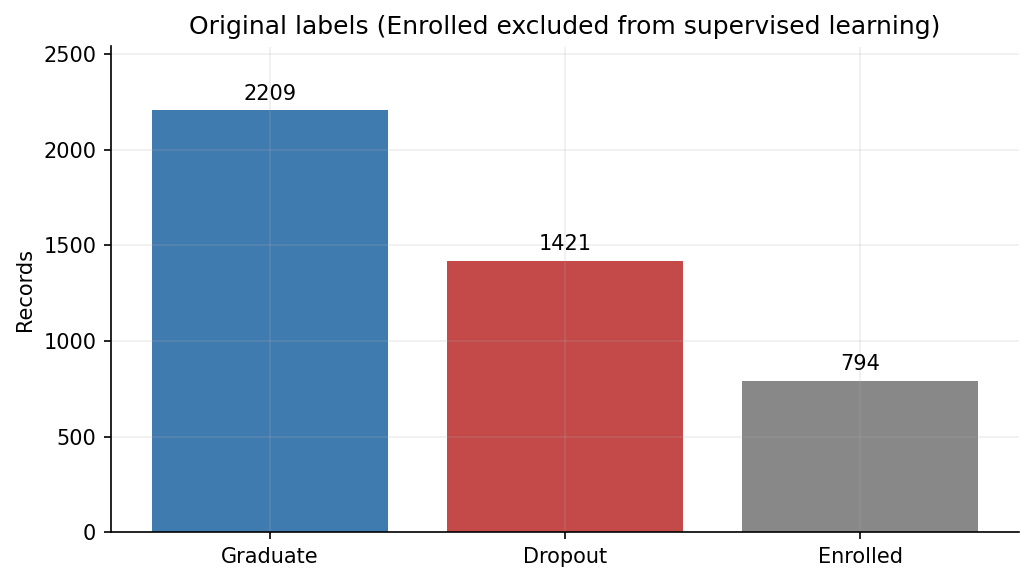

In [12]:
plot = results["output_dir"] / "plots" / "01_class_distribution.png"
if plot.exists():
    display(Image(filename=str(plot)))

### Training and validation learning curves

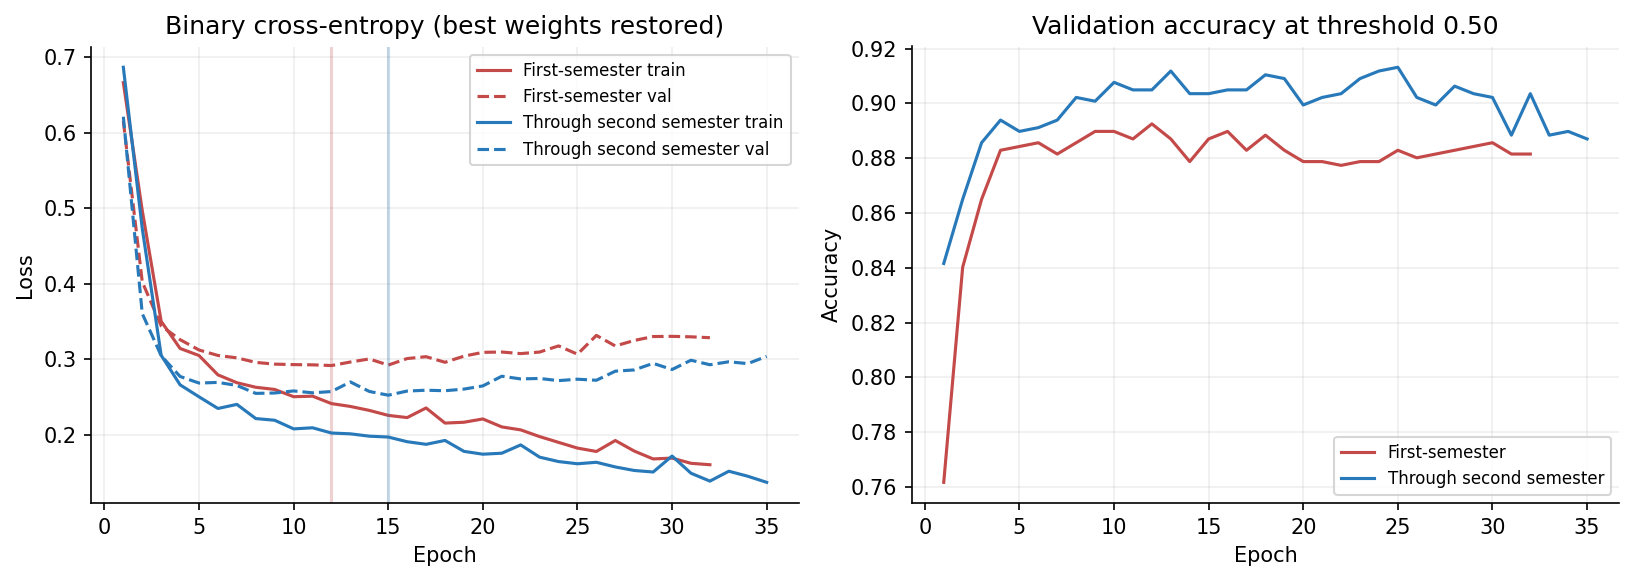

In [13]:
plot = results["output_dir"] / "plots" / "02_training_curves.png"
if plot.exists():
    display(Image(filename=str(plot)))

### Test ROC curves and logistic baseline

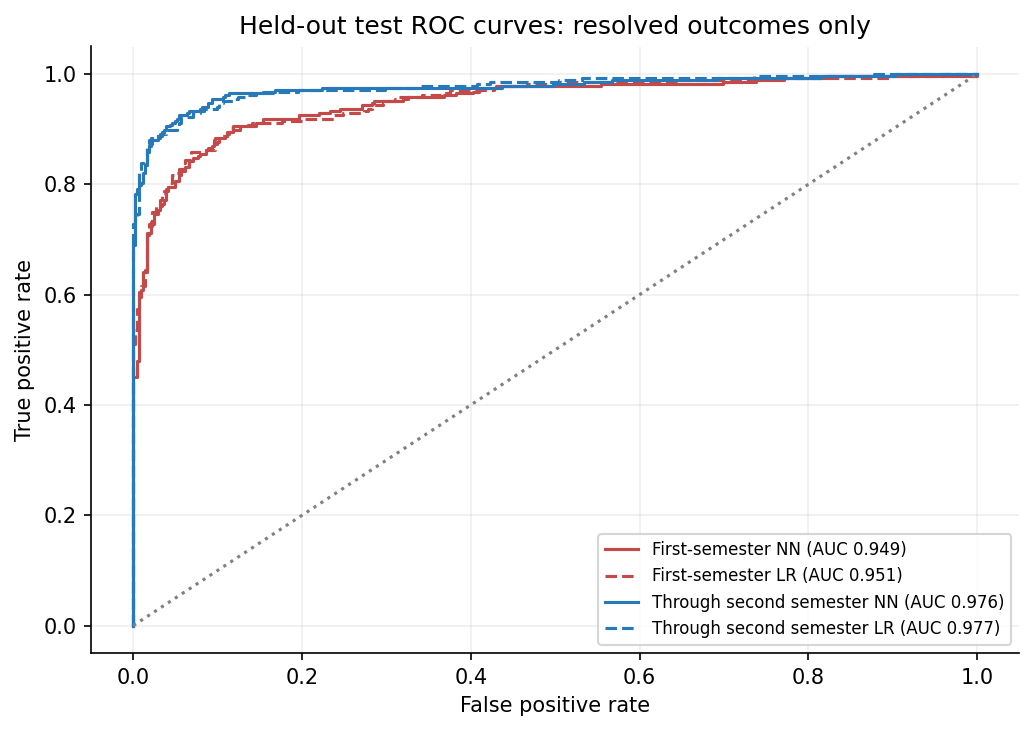

In [14]:
plot = results["output_dir"] / "plots" / "03_roc_curves.png"
if plot.exists():
    display(Image(filename=str(plot)))

### Test confusion matrices

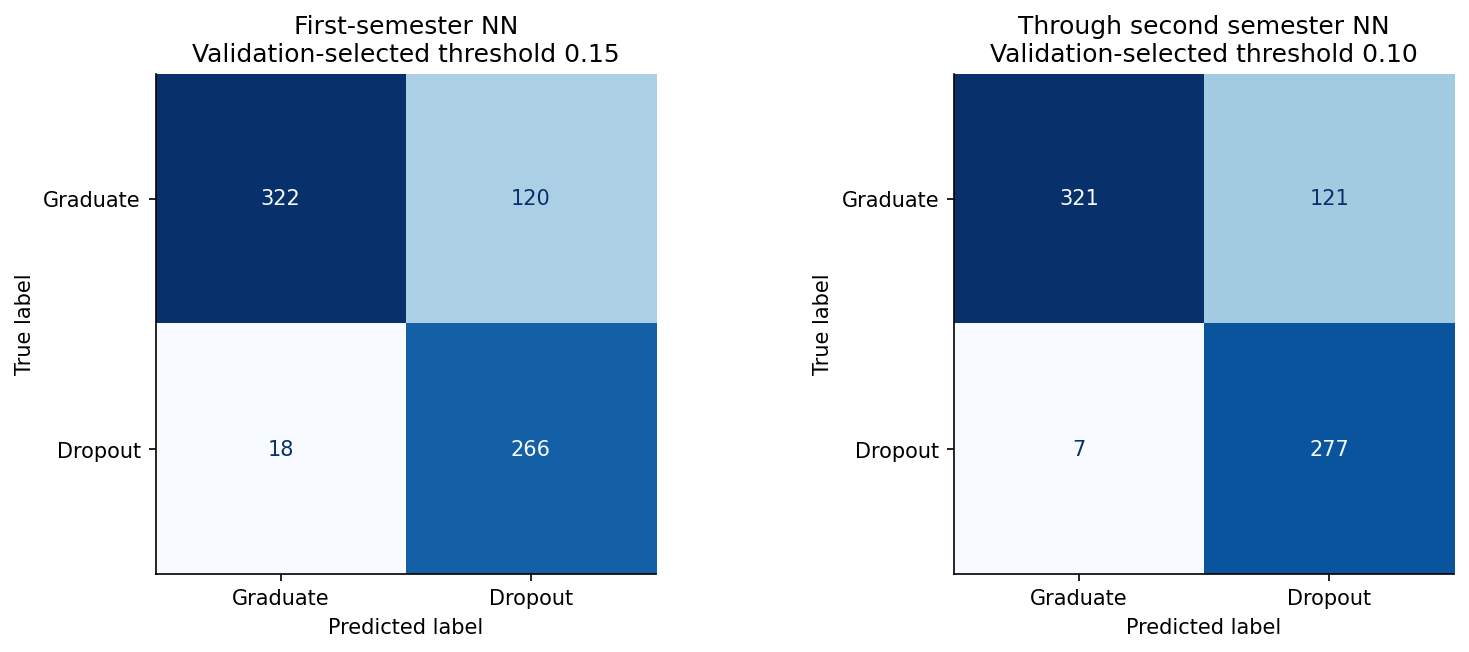

In [15]:
plot = results["output_dir"] / "plots" / "04_confusion_matrices.png"
if plot.exists():
    display(Image(filename=str(plot)))

### Validation-only threshold selection

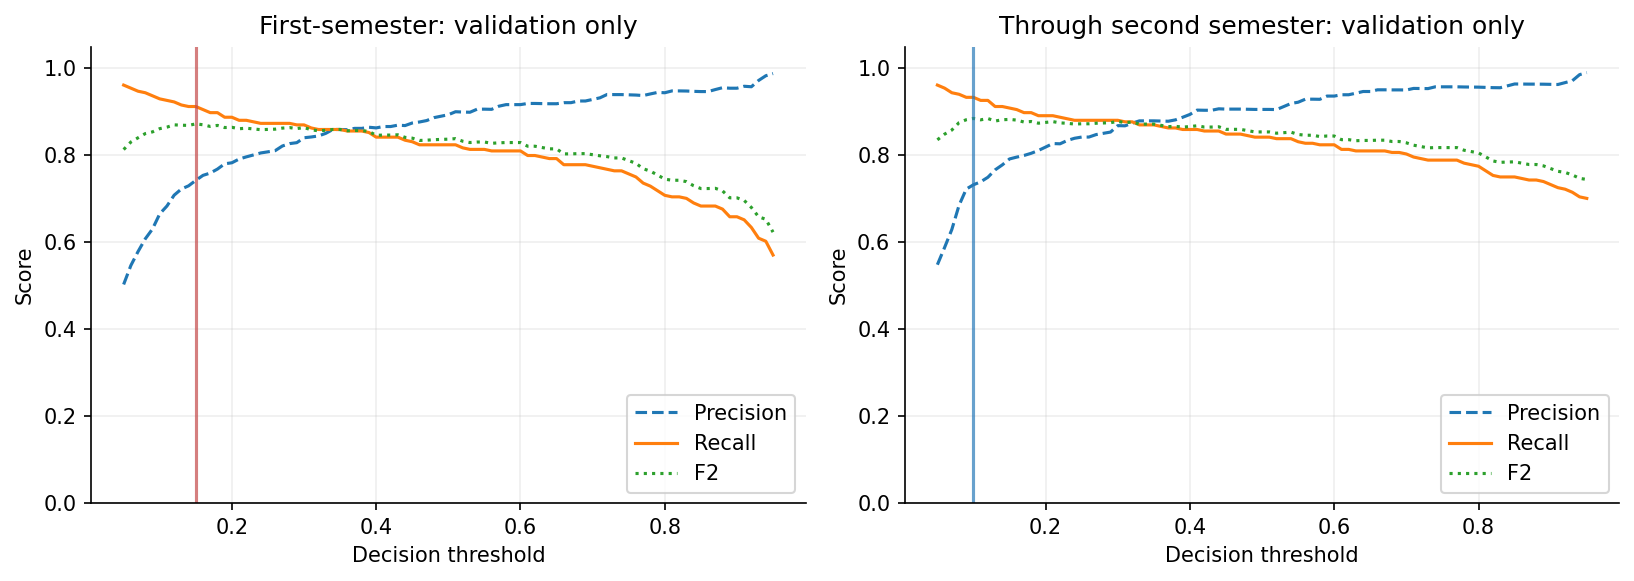

In [16]:
plot = results["output_dir"] / "plots" / "05_threshold_tradeoff.png"
if plot.exists():
    display(Image(filename=str(plot)))

### Test dropout score distribution

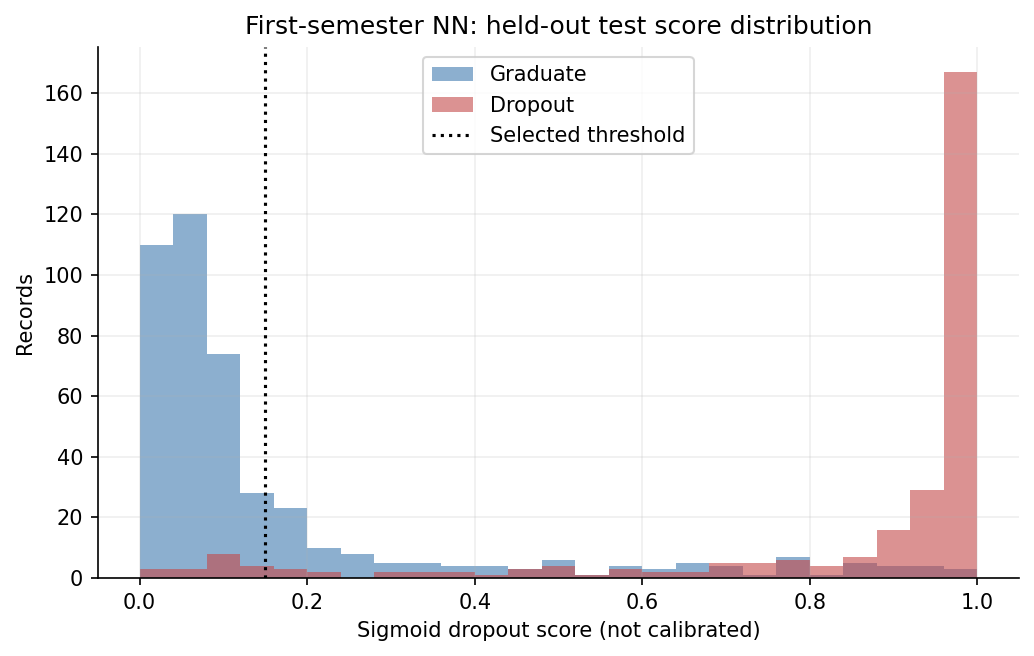

In [17]:
plot = results["output_dir"] / "plots" / "06_risk_distribution.png"
if plot.exists():
    display(Image(filename=str(plot)))

### Development-only cross-validation

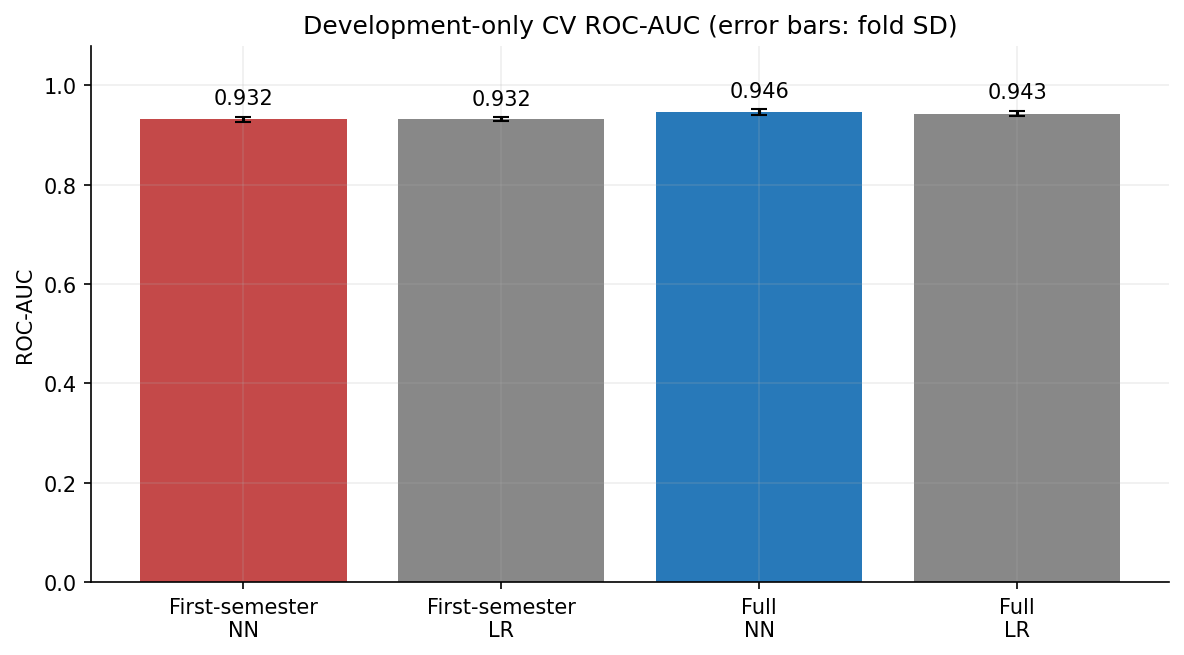

In [18]:
plot = results["output_dir"] / "plots" / "07_cv_comparison.png"
if plot.exists():
    display(Image(filename=str(plot)))

### Permutation importance

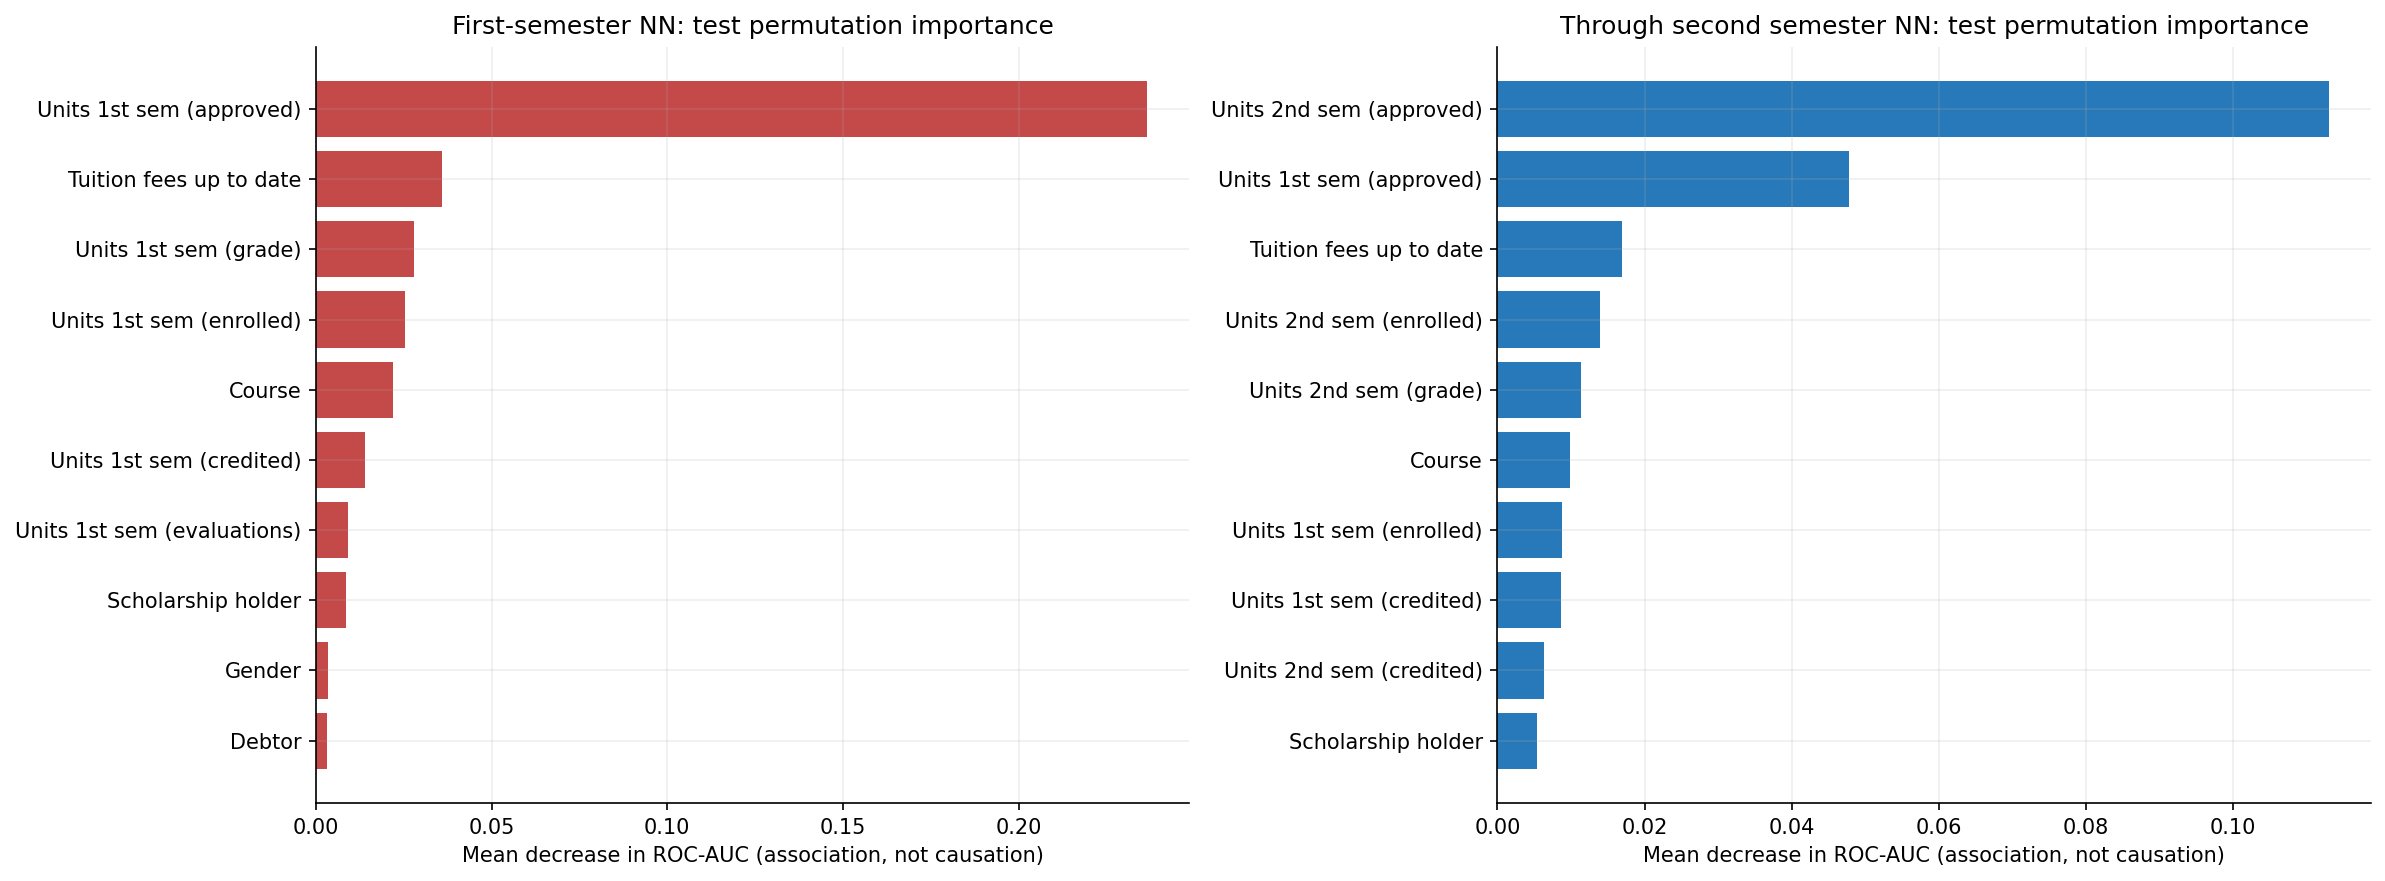

In [19]:
plot = results["output_dir"] / "plots" / "08_feature_importance.png"
if plot.exists():
    display(Image(filename=str(plot)))

### Descriptive subgroup audit

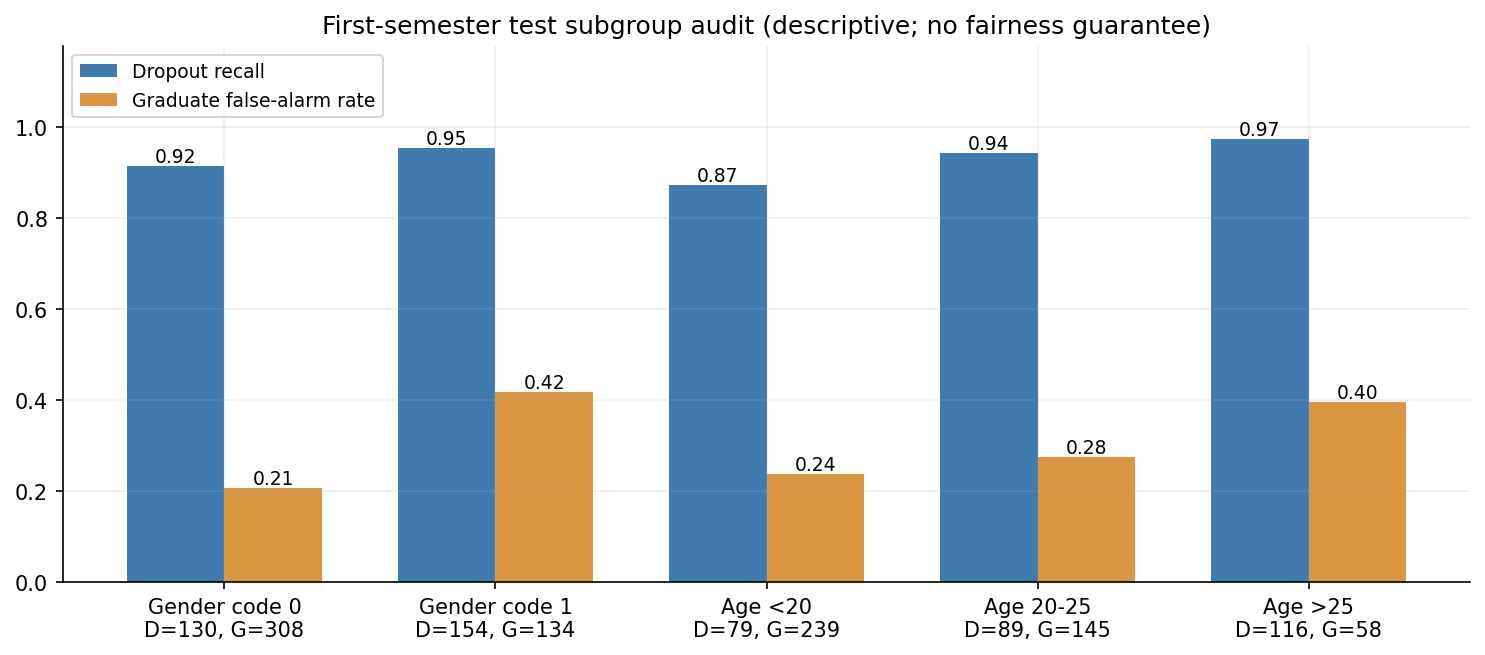

In [20]:
plot = results["output_dir"] / "plots" / "09_fairness.png"
if plot.exists():
    display(Image(filename=str(plot)))

## 10. Demonstrate saved-model prediction
This cell scores the supplied records with the saved first-semester model to verify the inference path. It is a technical demonstration, not a second evaluation; some input rows were used for training. Actual held-out metrics are in Section 9. In practice, replace `data.csv` with a CSV containing new students and the same first-semester feature columns.

In [21]:
demo_predictions = predict_new_students(
    PROJECT_DIR / "data.csv", PROJECT_DIR / "outputs" / "models",
    PROJECT_DIR / "outputs" / "saved_model_prediction_demo.csv")
display(demo_predictions.head(10))

Saved 4424 student scores to C:\Users\gisha\OneDrive\Documents\ChatGPT\STUDY\output\student_dropout_project\outputs\saved_model_prediction_demo.csv


,source_row_id,dropout_score,decision_threshold,mentoring_flag,support_priority
711,712,0.999972,0.15,True,Review for mentoring
1357,1358,0.999942,0.15,True,Review for mentoring
3714,3715,0.999939,0.15,True,Review for mentoring
3493,3494,0.999938,0.15,True,Review for mentoring
2448,2449,0.999934,0.15,True,Review for mentoring
3548,3549,0.999931,0.15,True,Review for mentoring
689,690,0.999926,0.15,True,Review for mentoring
3077,3078,0.999923,0.15,True,Review for mentoring
3874,3875,0.999919,0.15,True,Review for mentoring
4000,4001,0.999919,0.15,True,Review for mentoring


## Conclusion and limitations
Compare the measured first-semester NN and full NN results above; later academic information may improve discrimination but is available later for intervention. Compare both networks to logistic regression honestly even if the baseline is better. Explain dropout recall and false alarms using the confusion matrices.

This is retrospective evaluation on a single supplied cohort. Enrolled outcomes are unresolved; excluding them changes the population, and scores for those students require future validation. No temporal or external-institution test is possible from this CSV. Scores are uncalibrated, feature importance is associative, and subgroup estimates may be unstable. Data availability at the intervention date needs verification. Social value comes from offering timely mentoring and financial/academic support, with human review and respectful handling of student information.

### Source and attribution
The supplied `data.csv` is used unchanged; its exact Kaggle listing was not supplied. Its schema and label counts match the commonly circulated student-dropout dataset. Original dataset reference: Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021), *Predict Students’ Dropout and Academic Success*, UCI Machine Learning Repository, [DOI: 10.24432/C5MC89](https://doi.org/10.24432/C5MC89), CC BY 4.0. UCI currently lists 36 features; this supplied file has 34, so no absent features were invented. Category IDs are retained as supplied; do not assume their numeric codes equal the original UCI category dictionary.

This submission builds on the team's supplied `OCTOBER_14.ipynb`, `dropout_prediction.py`, and plot structure, with revised implementation and evaluation. See `SUBMISSION_GUIDE.txt` for commands and viva preparation.